# 04. Cohortes: supervivencia de largo plazo

Cuántos negocios de cada generación siguen vivos en ediciones posteriores.

In [1]:
import sqlite3
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

DB = Path("data/denue.db")
if not DB.exists():
    DB = Path("../data/denue.db")

EDICIONES = ["2022_11", "2023_11", "2024_11", "2025_05"]
ETIQUETAS = ["nov-2022", "nov-2023", "nov-2024", "may-2025"]
TRANSICIONES = [("2022_11", "2023_11"), ("2023_11", "2024_11"), ("2024_11", "2025_05")]

con = sqlite3.connect(DB)
datos = {ed: pd.read_sql(f"SELECT * FROM denue_{ed}", con) for ed in EDICIONES}
trans = {}
for e1, e2 in TRANSICIONES:
    s = pd.read_sql(f"SELECT * FROM t_{e1}__{e2}_sobrevivientes", con)
    n = pd.read_sql(f"SELECT * FROM t_{e1}__{e2}_nacimientos", con)
    m = pd.read_sql(f"SELECT * FROM t_{e1}__{e2}_muertes", con)
    trans[(e1, e2)] = (s, n, m)
cohortes = pd.read_sql("SELECT * FROM cohortes", con)
con.close()

print("Ediciones cargadas:", {ed: len(datos[ed]) for ed in EDICIONES})


Ediciones cargadas: {'2022_11': 41638, '2023_11': 41783, '2024_11': 46923, '2025_05': 47408}


## 1. Presencia en las ediciones

In [2]:
total = len(cohortes)
en_todas = int((cohortes[['en_2022_11', 'en_2023_11', 'en_2024_11', 'en_2025_05']].sum(axis=1) == 4).sum())
print(f'Total CLEEs únicos: {total:,}')
print(f'Presentes en las 4 ediciones: {en_todas:,} ({en_todas/total*100:.1f}%)')
print()
for ed in EDICIONES:
    c = cohortes[cohortes['cohorte'] == ed]
    ultima = EDICIONES[-1]
    s = int(c[f'en_{ultima}'].sum()) if len(c) else 0
    print(f'Cohorte {ed}: {len(c):,} -> sobreviven en {ultima}: {s:,} ({s/len(c)*100:.1f}%)' if len(c) else f'Cohorte {ed}: 0')

Total CLEEs únicos: 66,991
Presentes en las 4 ediciones: 24,040 (35.9%)

Cohorte 2022_11: 41,638 -> sobreviven en 2025_05: 25,917 (62.2%)
Cohorte 2023_11: 2,934 -> sobreviven en 2025_05: 1,039 (35.4%)
Cohorte 2024_11: 20,070 -> sobreviven en 2025_05: 18,103 (90.2%)
Cohorte 2025_05: 2,349 -> sobreviven en 2025_05: 2,349 (100.0%)


## 2. Curva de supervivencia de la cohorte 2022

nov-2022: 100.0%
nov-2023: 93.3%
nov-2024: 62.0%
may-2025: 62.2%


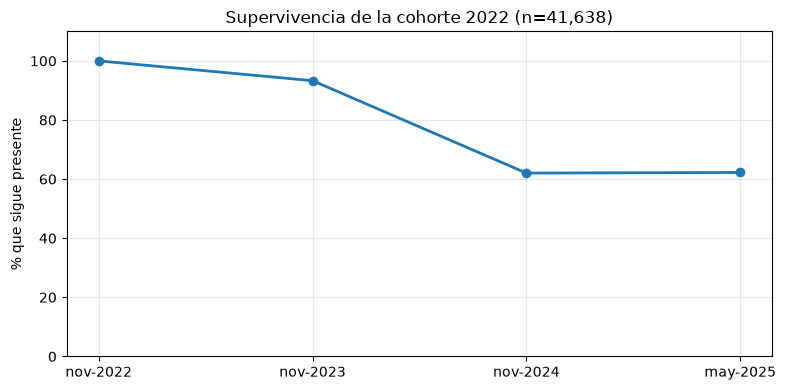

In [3]:
c22 = cohortes[cohortes['cohorte'] == '2022_11']
n0 = len(c22)
pts = [100] + [int(c22[f'en_{ed}'].sum()) / n0 * 100 for ed in EDICIONES[1:]]
for ed, p in zip(ETIQUETAS, pts):
    print(f'{ed}: {p:.1f}%')

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ETIQUETAS, pts, marker='o', linewidth=2, color='#1f77b4')
ax.set_ylim(0, 110)
ax.set_title(f'Supervivencia de la cohorte 2022 (n={n0:,})')
ax.set_ylabel('% que sigue presente')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Supervivencia 2022→2025 por sector de servicios y grupo Tren Maya

In [4]:
def supervivencia_2025(mask):
    sub = cohortes[mask]
    if len(sub) == 0:
        return 0, 0
    return len(sub), int(sub['en_2025_05'].sum()) / len(sub) * 100

print('Sector de servicios (cohorte 2022 -> 2025):')
for nivel in ['nucleo', 'ampliado', 'excluido', 'resto']:
    n, p = supervivencia_2025((cohortes['cohorte'] == '2022_11') & (cohortes['sector_servicios'] == nivel))
    print(f'  {nivel:<10} n={n:>6,}  supervivencia={p:.1f}%')

print('Grupo Tren Maya (cohorte 2022 -> 2025):')
for g in ['A', 'B', 'C']:
    n, p = supervivencia_2025((cohortes['cohorte'] == '2022_11') & (cohortes['grupo_tren'] == g))
    print(f'  Grupo {g}      n={n:>6,}  supervivencia={p:.1f}%')

Sector de servicios (cohorte 2022 -> 2025):
  nucleo     n= 5,425  supervivencia=56.0%
  ampliado   n=   357  supervivencia=61.3%
  excluido   n=    15  supervivencia=26.7%
  resto      n=35,841  supervivencia=63.2%
Grupo Tren Maya (cohorte 2022 -> 2025):
  Grupo A      n=25,843  supervivencia=62.6%


  Grupo B      n=13,421  supervivencia=61.0%


  Grupo C      n= 2,374  supervivencia=65.5%
